In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def sigma(x):
    s = 1/(1 + np.exp(-x))
    return s

def sigma_der(x):
    s = np.exp(-x)/(1+np.exp(-x))**2
    return s

In [3]:
def det_activations(inputs, weights, biases):
    
    activations = []
    activations.append(np.dot(weights[0],inputs) + biases[0])
    
    for i in range(1,len(biases)):

        activations.append(np.dot(weights[i],activations[i-1]) + biases[i])

    activations = [sigma(act) for act in activations]
    activations = [np.round(act, 3) for act in activations]
        
    return activations

In [4]:
def grad(activations, weights, biases, inputs, outputs):
    
    grad_activation = [0*act for act in activations]
    grad_bias = [0*bias for bias in biases]
    grad_weight = [0*weight for weight in weights]
    
    for k in range(len(biases[-2])):
        grad_activation[-2][k] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * weights[-1][j][k] for j in range(len(outputs))])

    for i in range(len(biases[-3])):
        grad_activation[-3][i] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * weights[-2][k][i] for k in range(len(biases[-2]))]) for j in range(len(outputs))])

    for m in range(len(biases[-4])):
        grad_activation[-4][m] = sum([2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * sum([weights[-1][j][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + 
                                    biases[-2][k]) * sum([weights[-2][k][i] * sigma_der(np.dot(weights[-3][i], activations[-4]) + 
                                    biases[-3][i]) * weights[-3][i][m] for i in range(len(biases[-3]))]) for k in range(len(biases[-2]))]) 
                                      for j in range(len(outputs))])
        
    
    for j in range(len(outputs)):
        grad_bias[-1][j] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                biases[-1][j])

    for k in range(len(biases[-2])):
        grad_bias[-2][k] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k])
    
    for k in range(len(biases[-3])):
        grad_bias[-3][k] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k])

    for k in range(len(biases[-4])):
        grad_bias[-4][k] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k])

    
    
    
    for j in range(len(outputs)):
        for k in range(len(biases[-2])):
            grad_weight[-1][j][k] =  2 * (activations[-1][j] - outputs[j]) * sigma_der(np.dot(weights[-1][j], activations[-2]) + 
                                    biases[-1][j]) * activations[-2][k]

    for k in range(len(biases[-2])):
        for i in range(len(biases[-3])):
            grad_weight[-2][k][i] =  grad_activation[-2][k] * sigma_der(np.dot(weights[-2][k], activations[-3]) + biases[-2][k]) * activations[-3][i]

    for k in range(len(biases[-3])):
        for i in range(len(biases[-4])):
            grad_weight[-3][k][i] =  grad_activation[-3][k] * sigma_der(np.dot(weights[-3][k], activations[-4]) + biases[-3][k]) * activations[-4][i]

    for k in range(len(biases[-4])):
        for i in range(len(inputs)):
            grad_weight[-4][k][i] =  grad_activation[-4][k] * sigma_der(np.dot(weights[-4][k], inputs) + biases[-4][k]) * inputs[i]
            
    
    return grad_activation, grad_weight, grad_bias

In [70]:
def neural_network(inputs, outputs, nodes_hidden_layers, max_bias, max_weight, learning_rate, iterations):

    biases = []
    for i in range(len(nodes_hidden_layers)):
        biases.append(np.random.uniform(-max_bias, max_bias, nodes_hidden_layers[i]))

    biases.append(np.random.uniform(-max_bias, max_bias, len(outputs[0])))

    
    weights = []
    weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[0], len(inputs[0]))))
    
    for i in range(len(nodes_hidden_layers) - 1):
        weights.append(np.random.uniform(-max_weight, max_weight, (nodes_hidden_layers[i+1], nodes_hidden_layers[i])))

    weights.append(np.random.uniform(-max_weight, max_weight, (len(outputs[0]), nodes_hidden_layers[-1])))

    cost = []

    
    for k in range(iterations):

        iter_cost = 0

        gr_b = [0*bias for bias in biases]
        gr_w = [0*weight for weight in weights]
        gr_act = gr_b
        
        for j in range(inputs.shape[0]):        
            
            activations = det_activations(inputs[j], weights, biases)
            iter_cost +=  (1/inputs.shape[0]) * sum([(activations[-1].tolist()[i] - outputs[j][i])**2 for i in range(len(outputs[j]))])
        
            gr_act_p, gr_w_p, gr_b_p = grad(activations, weights, biases, inputs[j], outputs[j])

            gr_b = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_b, gr_b_p)]
            gr_w = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_w, gr_w_p)]
            gr_act = [g + (1/inputs.shape[0])*gp for g, gp in zip(gr_act, gr_act_p)]
            
        weights = [w - learning_rate * gw for w, gw in zip(weights, gr_w)]
        biases = [b - learning_rate * gb for b, gb in zip(biases, gr_b)]

        cost.append(iter_cost)

    return activations, weights, biases, cost

In [22]:
inputs = np.random.rand(4,20)
outputs = [[1, 0.3, 0.2, 0.5, 0.6, 0.8], [0.3, 0.8, 0.14, 0.9, 0.21, 0.5], [0.1, 0.9, 0.13, 0.98, 0.4, 0.5], 
           [0.2, 0.22, 0.222, 0.4, 0.05, 0.6]]

In [74]:
activations, weights, biases, cost = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 1000) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

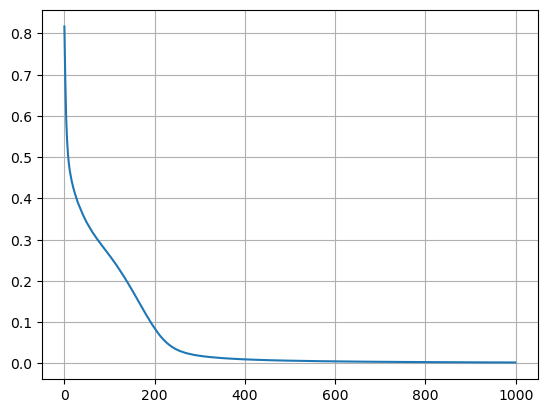

In [75]:
plt.plot(cost);
plt.grid();

In [76]:
activations

[array([0.191, 0.186, 0.626, 0.255, 0.674]),
 array([0.75 , 0.432, 0.615, 0.668, 0.89 ]),
 array([0.696, 0.039, 0.328, 0.199, 0.79 ]),
 array([0.209, 0.22 , 0.22 , 0.4  , 0.05 , 0.599])]

In [78]:
activations, weights, biases, cost_a = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 1, 400) 
activations, weights, biases, cost_b = neural_network(inputs, outputs, [5, 5, 5], 1, 1, 1, 400) 
activations, weights, biases, cost_c = neural_network(inputs, outputs, [7, 7, 7], 1, 1, 1, 400) 
activations, weights, biases, cost_d = neural_network(inputs, outputs, [10, 10, 10], 1, 1, 1, 400) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

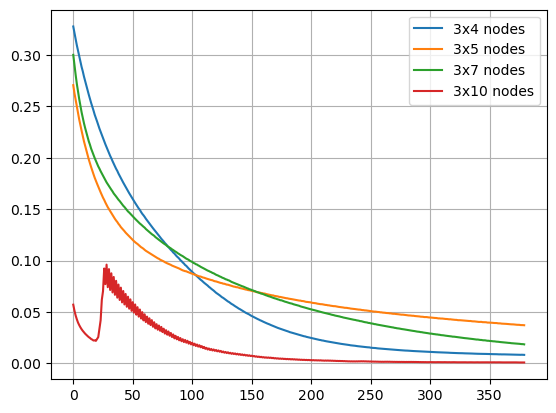

In [80]:
plt.plot(cost_a[20:], label="3x4 nodes");
plt.plot(cost_b[20:], label="3x5 nodes");
plt.plot(cost_c[20:], label="3x7 nodes");
plt.plot(cost_d[20:], label="3x10 nodes");
plt.grid();
plt.legend();

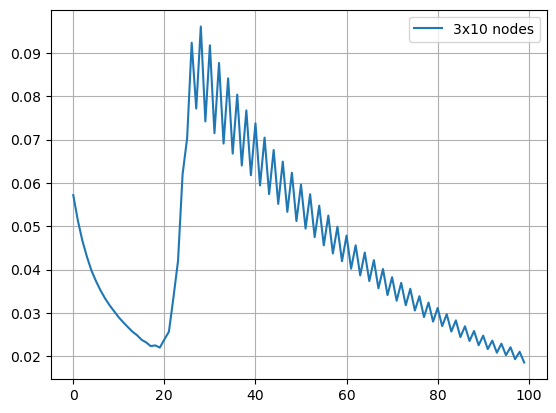

In [81]:
plt.plot(cost_d[20:120], label="3x10 nodes");
plt.grid();
plt.legend();

In [82]:
activations, weights, biases, cost_a = neural_network(inputs, outputs, [4, 4, 4], 0.5, 1, 1, 400) 
activations, weights, biases, cost_b = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 1, 400) 
activations, weights, biases, cost_c = neural_network(inputs, outputs, [4, 4, 4], 2, 1, 1, 400) 
activations, weights, biases, cost_d = neural_network(inputs, outputs, [4, 4, 4], 5, 1, 1, 400) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

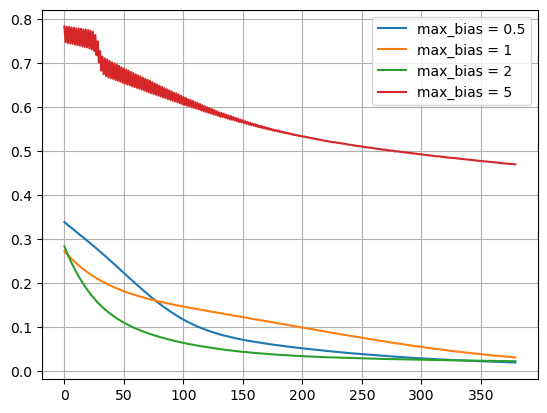

In [83]:
plt.plot(cost_a[20:], label="max_bias = 0.5");
plt.plot(cost_b[20:], label="max_bias = 1");
plt.plot(cost_c[20:], label="max_bias = 2");
plt.plot(cost_d[20:], label="max_bias = 5");
plt.grid();
plt.legend();

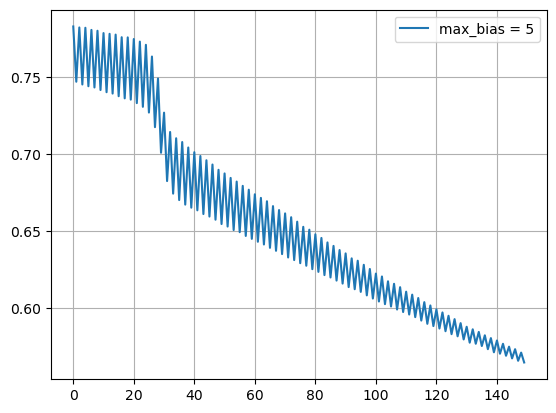

In [84]:
plt.plot(cost_d[20:170], label="max_bias = 5");
plt.grid();
plt.legend();

In [85]:
activations, weights, biases, cost_a = neural_network(inputs, outputs, [4, 4, 4], 1, 0.5, 1, 400) 
activations, weights, biases, cost_b = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 1, 400) 
activations, weights, biases, cost_c = neural_network(inputs, outputs, [4, 4, 4], 1, 2, 1, 400) 
activations, weights, biases, cost_d = neural_network(inputs, outputs, [4, 4, 4], 1, 5, 1, 400) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

/var/folders/tk/6312j0x51lv1_71j8_phv3bc0000gn/T/ipykernel_57052/1919106164.py:2: RuntimeWarning: overflow encountered in exp
  s = 1/(1 + np.exp(-x))


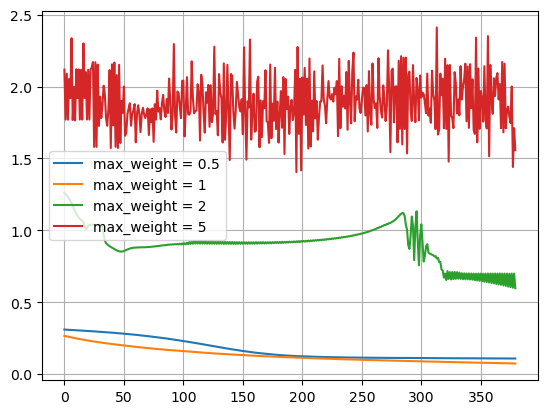

In [86]:
plt.plot(cost_a[20:], label="max_weight = 0.5");
plt.plot(cost_b[20:], label="max_weight = 1");
plt.plot(cost_c[20:], label="max_weight = 2");
plt.plot(cost_d[20:], label="max_weight = 5");
plt.grid();
plt.legend();

In [87]:
activations, weights, biases, cost_a = neural_network(inputs, outputs, [4, 4, 4], 1, 0.2, 1, 400) 
activations, weights, biases, cost_b = neural_network(inputs, outputs, [4, 4, 4], 1, 0.4, 1, 400) 
activations, weights, biases, cost_c = neural_network(inputs, outputs, [4, 4, 4], 1, 0.7, 1, 400) 
activations, weights, biases, cost_d = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 1, 400) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

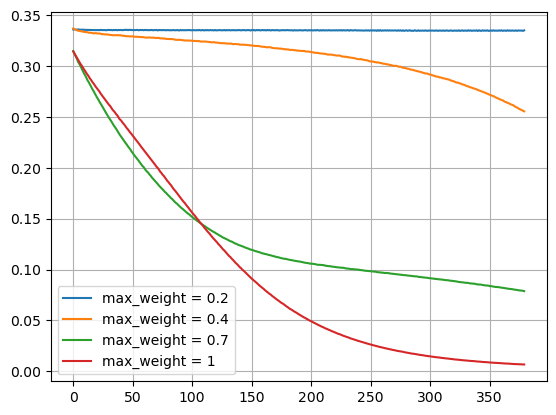

In [88]:
plt.plot(cost_a[20:], label="max_weight = 0.2");
plt.plot(cost_b[20:], label="max_weight = 0.4");
plt.plot(cost_c[20:], label="max_weight = 0.7");
plt.plot(cost_d[20:], label="max_weight = 1");
plt.grid();
plt.legend();

In [89]:
activations, weights, biases, cost_a = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 0.5, 400) 
activations, weights, biases, cost_b = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 1, 400) 
activations, weights, biases, cost_c = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 2, 400) 
activations, weights, biases, cost_d = neural_network(inputs, outputs, [4, 4, 4], 1, 1, 5, 400) 
#laatste 4: max_bias, max_weight, learning_rate, iterations

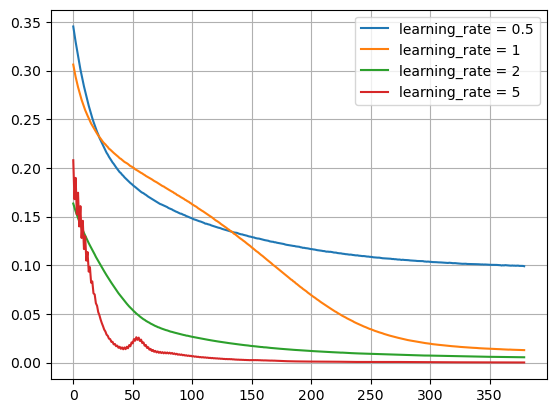

In [90]:
plt.plot(cost_a[20:], label="learning_rate = 0.5");
plt.plot(cost_b[20:], label="learning_rate = 1");
plt.plot(cost_c[20:], label="learning_rate = 2");
plt.plot(cost_d[20:], label="learning_rate = 5");
plt.grid();
plt.legend();